In [3]:
import os
import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import torch
import torch._dynamo
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor

import math
import numpy as np
import matplotlib.pyplot as plt

from src_toys.fields import PFGMPPField, Field
from src_toys.interpolants import LinearInterpolant, QuadraticSigmaSchedule, SineCosineInterpolant

from IPython.display import clear_output
from torch.utils.data import DataLoader, TensorDataset

from tqdm.auto import tqdm

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---

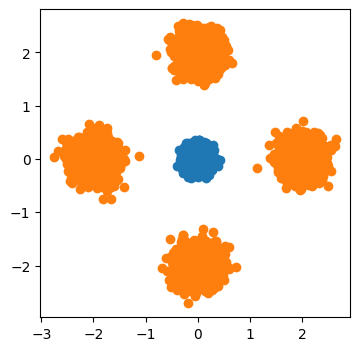

In [4]:
def get_dataset(ds_name, aux_dim=None, n_blobs=None, r_blobs=None, sigma_blobs=None):
    if ds_name == "gaussian":
        sigma = .1
        ds_size = 10_000
        X = np.random.randn(ds_size, 2) * sigma
        Y = None

    elif ds_name == "gaussians3":
        ds_size = 5_000
        centers = []
        for i in range(n_blobs):
            angle = np.pi / 2 - 2 * np.pi * i / n_blobs
            centers.append([r_blobs * np.cos(angle), r_blobs * np.sin(angle)])

        samples_per_blob = ds_size // n_blobs
        X_list, Y_list = [], []
        for i, mu in enumerate(centers):
            Xi = np.random.randn(samples_per_blob, 2) * sigma_blobs + np.array(mu)
            X_list.append(Xi)
            Y_list.append(np.ones(samples_per_blob) * i)

        X = np.concatenate(X_list).astype(np.float32)
        Y = np.concatenate(Y_list)

    return X.astype(np.float32), Y

### dataset 0 ###
X0, Y0 = get_dataset("gaussian")

plt.figure(figsize=(4, 4))
plt.scatter(x=X0[:, 0], y=X0[:, 1])

### dataset 1 ###
X1, Y1 = get_dataset("gaussians3", n_blobs=4, r_blobs=2., sigma_blobs=0.2)

plt.scatter(x=X1[:, 0], y=X1[:, 1])
plt.show()

In [5]:
class SinTimeEmbed(nn.Module):
    def __init__(self, dim=64, max_freq=64.0):
        super().__init__()
        self.register_buffer("freqs", torch.exp(torch.linspace(0., math.log(max_freq), dim // 2)))
        self.dim = dim
        
    def forward(self, z):
        ang = z[:, None] * self.freqs[None, :] * 2 * math.pi
        emb = torch.cat([torch.sin(ang), torch.cos(ang)], dim=-1)
        if emb.shape[-1] < self.dim:
            emb = F.pad(emb, (0, self.dim - emb.shape[-1]))
        return emb

class VelocityMLP(nn.Module):
    def __init__(self, x_dim=2, t_dim=64, hidden=256, layers=3, out_dim=None):
        super().__init__()
        self.temb = SinTimeEmbed(t_dim)
        in_dim = x_dim + t_dim
        mods = []

        for i in range(layers):
            mods += [nn.Linear(in_dim if i==0 else hidden, hidden), nn.SiLU()]
        self.backbone = nn.Sequential(*mods)

        if out_dim is None:
            out_dim = x_dim
        self.out = nn.Linear(hidden, out_dim)

        nn.init.xavier_uniform_(self.out.weight, gain=0.1)
        nn.init.zeros_(self.out.bias)

    def forward(self, x, z):
        te = self.temb(z)
        h = torch.cat([x, te], dim=-1)
        return self.out(self.backbone(h))

In [6]:
class SinglePointExEzLoss:
    """
    Single-point target for ExEz parameterisation.
    target = velocity(x_t, z, x0, x1) = ratio(z)*(x_t - I(z,x0,x1)) + I'(z,x0,x1)
    Magnitude cancels in Ex/Ez for a single point.
    """
    def __call__(self, net, field_to_sample_xt, field_to_compute_E, x0, x1, eps=1e-3):
        z = eps + torch.rand(x0.shape[0], device=x0.device) * (1 - 2 * eps)
        x = field_to_sample_xt.sample(z, x0, x1)
        v_target = field_to_compute_E.velocity(x, z, x0, x1)
        v_pred = net(x, z)
        return F.mse_loss(v_pred, v_target)


class SinglePointENormELoss:
    """
    Single-point target for ENorm parameterisation.
    For single point, mag cancels in normalization:
        E = [v, 1] / ||[v, 1]||
    where v = velocity(x_t, z, x0, x1).
    """
    def __call__(self, net, field_to_sample_xt, field_to_compute_E, x0, x1, eps=1e-3):
        z = eps + torch.rand(x0.shape[0], device=x0.device) * (1 - 2 * eps)
        x = field_to_sample_xt.sample(z, x0, x1)
        v = field_to_compute_E.velocity(x, z, x0, x1)
        E = torch.cat([v, torch.ones(v.shape[0], 1, device=v.device)], dim=-1)
        E_target = E / E.norm(dim=-1, keepdim=True)
        E_pred = net(x, z)
        return F.mse_loss(E_pred, E_target)

---
## Experiments Setup (Single-Point Target)

In [7]:
lin_field = PFGMPPField(
    interpolant=LinearInterpolant(),
    sigma_schedule=QuadraticSigmaSchedule(0.05),
    data_dim=2,
)

sine_field = PFGMPPField(
    interpolant=SineCosineInterpolant(),
    sigma_schedule=QuadraticSigmaSchedule(0.05),
    data_dim=2,
)

### Experiments with correct p_vol: #####

experiment1 = {
    "field_to_sample_xt": lin_field,
    "field_to_compute_E": lin_field,
    "model": VelocityMLP(x_dim=2, out_dim=2),
    "loss_fn": SinglePointExEzLoss(),
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

experiment2 = {
    "field_to_sample_xt": sine_field,
    "field_to_compute_E": sine_field,
    "model": VelocityMLP(x_dim=2, out_dim=2),
    "loss_fn": SinglePointExEzLoss(),
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

experiment3 = {
    "field_to_sample_xt": lin_field,
    "field_to_compute_E": lin_field,
    "model": VelocityMLP(x_dim=2, out_dim=3),
    "loss_fn": SinglePointENormELoss(),
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

experiment4 = {
    "field_to_sample_xt": sine_field,
    "field_to_compute_E": sine_field,
    "model": VelocityMLP(x_dim=2, out_dim=3),
    "loss_fn": SinglePointENormELoss(),
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

### Experiments with wrong p_vol: #####

experiment5 = {
    "field_to_sample_xt": lin_field,
    "field_to_compute_E": sine_field,
    "model": VelocityMLP(x_dim=2, out_dim=2),
    "loss_fn": SinglePointExEzLoss(),
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

experiment6 = {
    "field_to_sample_xt": sine_field,
    "field_to_compute_E": lin_field,
    "model": VelocityMLP(x_dim=2, out_dim=2),
    "loss_fn": SinglePointExEzLoss(),
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

experiment7 = {
    "field_to_sample_xt": lin_field,
    "field_to_compute_E": sine_field,
    "model": VelocityMLP(x_dim=2, out_dim=3),
    "loss_fn": SinglePointENormELoss(),
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

experiment8 = {
    "field_to_sample_xt": sine_field,
    "field_to_compute_E": lin_field,
    "model": VelocityMLP(x_dim=2, out_dim=3),
    "loss_fn": SinglePointENormELoss(),
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

In [ ]:
def run_experiment(
    experiment: dict,
    X0, X1,
    exp_num: int = 0,
    n_epochs: int = 100,
    steps: int = 1000,
    log_every: int = 100,
    steps_ode_eval: int = 50,
    batch_size: int = 512,
    lr: float = 5e-4,
    checkpoint_dir: str = "checkpoints/singlesample",
    eval_every: int = 5,
):
    field_to_sample_xt = experiment["field_to_sample_xt"]
    field_to_compute_E = experiment["field_to_compute_E"]
    model = experiment["model"]
    loss_fn = experiment["loss_fn"]

    device = experiment.get("device", "cpu")
    use_enorm = isinstance(loss_fn, SinglePointENormELoss)

    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    dl0 = DataLoader(TensorDataset(torch.tensor(X0)), batch_size=batch_size, shuffle=True, drop_last=True)
    dl1 = DataLoader(TensorDataset(torch.tensor(X1)), batch_size=batch_size, shuffle=True, drop_last=True)

    for epoch in range(n_epochs):
        it0 = iter(dl0)
        it1 = iter(dl1)

        pbar = tqdm(range(1, steps + 1), desc=f"Epoch {epoch}")
        for step in pbar:
            try:
                (x0,) = next(it0)
            except StopIteration:
                it0 = iter(dl0)
                (x0,) = next(it0)
            try:
                (x1,) = next(it1)
            except StopIteration:
                it1 = iter(dl1)
                (x1,) = next(it1)

            x0 = x0.to(device)
            x1 = x1.to(device)

            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model, field_to_sample_xt, field_to_compute_E, x0, x1)
            loss.backward()
            optimizer.step()

            if step % log_every == 0:
                pbar.set_postfix(loss=f"{float(loss.detach()):.4f}")

        if (epoch + 1) % eval_every == 0:
            with torch.no_grad():
                B = 5000
                x = torch.tensor(X0[:B], device=device)
                z = torch.zeros(B, device=device)
                dz = 1.0 / steps_ode_eval
                for _ in range(steps_ode_eval):
                    if use_enorm:
                        E1 = model(x, z)
                        v1 = E1[:, :-1] / E1[:, -1:]
                        x_euler = x + dz * v1
                        z_next = (z + dz).clamp_(0.0, 1.0)
                        E2 = model(x_euler, z_next)
                        v2 = E2[:, :-1] / E2[:, -1:]
                    else:
                        v1 = model(x, z)
                        x_euler = x + dz * v1
                        z_next = (z + dz).clamp_(0.0, 1.0)
                        v2 = model(x_euler, z_next)
                    x = x + 0.5 * dz * (v1 + v2)
                    z = z_next

                samples = x.cpu()

            try:
                clear_output()
                plt.figure(figsize=(4, 4))
                plt.scatter(X1[:B, 0], X1[:B, 1], s=2, alpha=0.6)
                plt.scatter(samples[:, 0], samples[:, 1], s=2, alpha=0.6)
                plt.axis("equal")
                plt.tight_layout()
                plt.show()
            except Exception:
                pass

    os.makedirs(checkpoint_dir, exist_ok=True)
    torch.save(model.state_dict(), os.path.join(checkpoint_dir, f"exp{exp_num}.pt"))

    with torch.no_grad():
        B = 5000
        x = torch.tensor(X0[:B], device=device)
        z = torch.zeros(B, device=device)
        dz = 1.0 / steps_ode_eval
        for _ in range(steps_ode_eval):
            if use_enorm:
                E1 = model(x, z)
                v1 = E1[:, :-1] / E1[:, -1:]
                x_euler = x + dz * v1
                z_next = (z + dz).clamp_(0.0, 1.0)
                E2 = model(x_euler, z_next)
                v2 = E2[:, :-1] / E2[:, -1:]
            else:
                v1 = model(x, z)
                x_euler = x + dz * v1
                z_next = (z + dz).clamp_(0.0, 1.0)
                v2 = model(x_euler, z_next)
            x = x + 0.5 * dz * (v1 + v2)
            z = z_next
        samples = x.cpu()

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.scatter(X1[:B, 0], X1[:B, 1], s=2, alpha=0.6)
    ax.scatter(samples[:, 0], samples[:, 1], s=2, alpha=0.6)
    ax.axis("equal")
    fig.tight_layout()
    fig.savefig(os.path.join(checkpoint_dir, f"exp{exp_num}.png"))
    plt.close(fig)

    return model

In [ ]:
# for exp_num, exp in enumerate(
#     [
#         experiment1, experiment2, experiment3, experiment4,
#         experiment5, experiment6, experiment7, experiment8
#     ], start=1
# ):
#     run_experiment(
#         exp, X0, X1, exp_num=exp_num, steps_ode_eval=500, n_epochs=50, lr=5e-4,
#         checkpoint_dir="checkpoints_singlepoint_s0.05"
#     )

---
## W2 distances

In [11]:
import ot
import copy
import copy
import random
from statistics import mean, stdev

In [12]:

def sample_from_model(model, X0, use_enorm, steps_ode_eval=50, B=5000, device="cpu"):
    with torch.no_grad():
        x = torch.tensor(X0[:B], device=device)
        z = torch.zeros(B, device=device)
        dz = 1.0 / steps_ode_eval
        for _ in range(steps_ode_eval):
            if use_enorm:
                E1 = model(x, z)
                v1 = E1[:, :-1] / E1[:, -1:]
                x_euler = x + dz * v1
                z_next = (z + dz).clamp_(0.0, 1.0)
                E2 = model(x_euler, z_next)
                v2 = E2[:, :-1] / E2[:, -1:]
            else:
                v1 = model(x, z)
                x_euler = x + dz * v1
                z_next = (z + dz).clamp_(0.0, 1.0)
                v2 = model(x_euler, z_next)
            x = x + 0.5 * dz * (v1 + v2)
            z = z_next
    return x.cpu().numpy()


def compute_w2(model, X0, X1, use_enorm, steps_ode_eval=50, B=5000, device="cpu"):
    samples = sample_from_model(model, X0, use_enorm, steps_ode_eval, B, device)
    target  = X1[:B]
    a = np.ones(B) / B
    b = np.ones(B) / B
    M = ot.dist(samples, target, metric="sqeuclidean")
    w2_sq = ot.emd2(a, b, M)
    return float(np.sqrt(w2_sq))

In [13]:
exps = [
    experiment1, experiment2,
    experiment3, experiment4,
    experiment5, experiment6,
    experiment7, experiment8
]

In [16]:
k = 3
B_eval = min(5000, len(X0), len(X1))


def random_subset(arr, n):
    if len(arr) <= n:
        return arr
    idx = random.sample(range(len(arr)), n)
    if torch.is_tensor(arr):
        return arr[idx]
    if isinstance(arr, list):
        return [arr[i] for i in idx]
    return arr[idx]

checkpoint_dir = "checkpoints/singlesample"

for i, exp in enumerate(exps):
    path = f"{checkpoint_dir}/exp{i + 1}.pt"
    state = torch.load(path, map_location="cpu")
    model = copy.deepcopy(exp["model"])
    model.load_state_dict(state)
    model.eval()
    use_enorm = isinstance(exp["loss_fn"], SinglePointENormELoss)

    w2_values = []
    for _ in range(k):
        X0_sample = random_subset(X0, B_eval)
        X1_sample = random_subset(X1, B_eval)
        w2_values.append(compute_w2(model, X0_sample, X1_sample, use_enorm=use_enorm, B=B_eval, steps_ode_eval=50))

    w2_mean = mean(w2_values)
    w2_std = stdev(w2_values) if len(w2_values) > 1 else 0.0
    print(f"{i+1}| W2={w2_mean:.4f} +/- {w2_std:.4f}")

1| W2=0.7185 +/- 0.0343
2| W2=1.4033 +/- 0.0075
3| W2=0.2341 +/- 0.0516
4| W2=0.3148 +/- 0.0305
5| W2=1.1067 +/- 0.0027
6| W2=1.3174 +/- 0.0253
7| W2=0.6237 +/- 0.0342
8| W2=0.6979 +/- 0.2414


1) linear interp, Ex / Ez prediction, volume from linear interp (correct p_vol)
2) sine-cosine interp, Ex / Ez prediction, volume from sine-cosine interp (correct p_vol)
3) linear interp, E / ||E|| prediction, volume from linear interp (correct p_vol)
4) sine-cosine interp, E / ||E|| prediction, volume from sine-cosine interp (correct p_vol)

5) linear interp, Ex / Ez prediction, volume from sine-cosine interp (wrong p_vol)
6) sine-cosine interp, Ex / Ez prediction, volume from linear interp (wrong p_vol)
7) linear interp, E / ||E|| prediction, volume from sine-cosine interp (wrong p_vol)
8) sine-cosine interp, E / ||E|| prediction, volume from linear interp (wrong p_vol)